In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

## 1. ĐỌC DỮ LIỆU

In [2]:
print("ĐỌC DỮ LIỆU")
df = pd.read_excel(Path("..") / "data" / "processed" / "clean_data.xlsx")

print("Kích thước dữ liệu:", df.shape)

ĐỌC DỮ LIỆU
Kích thước dữ liệu: (720, 7)


## 2. KHAI BÁO BIẾN

In [3]:
dependent_vars = [
    "Fragrance",
    "Flavor",
    "Aftertaste",
    "Acidity",
    "Body",
    "Moisture"
]

group_var = "Origin"

## 3. KIỂM TRA NHÓM

In [4]:
print("\nSố lượng mẫu theo Origin:")
print(df[group_var].value_counts())


Số lượng mẫu theo Origin:
Origin
Mexico       236
Colombia     180
Guatemala    175
Brazil       129
Name: count, dtype: int64


## 4. BOXPLOT CHO TỪNG BIẾN

VẼ BOXPLOT


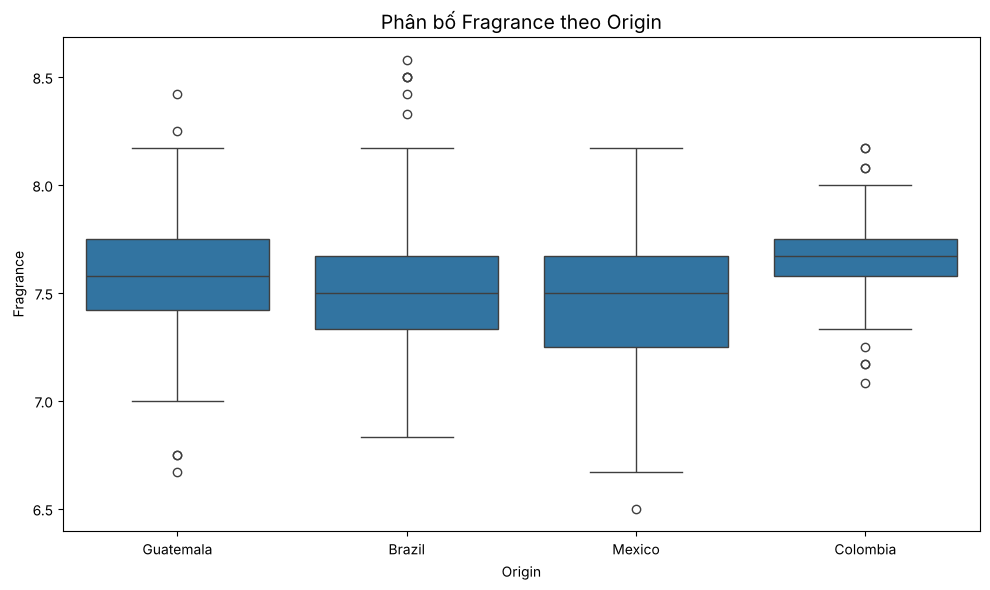

Đã lưu: ../figures/boxplots/boxplot_Fragrance.png


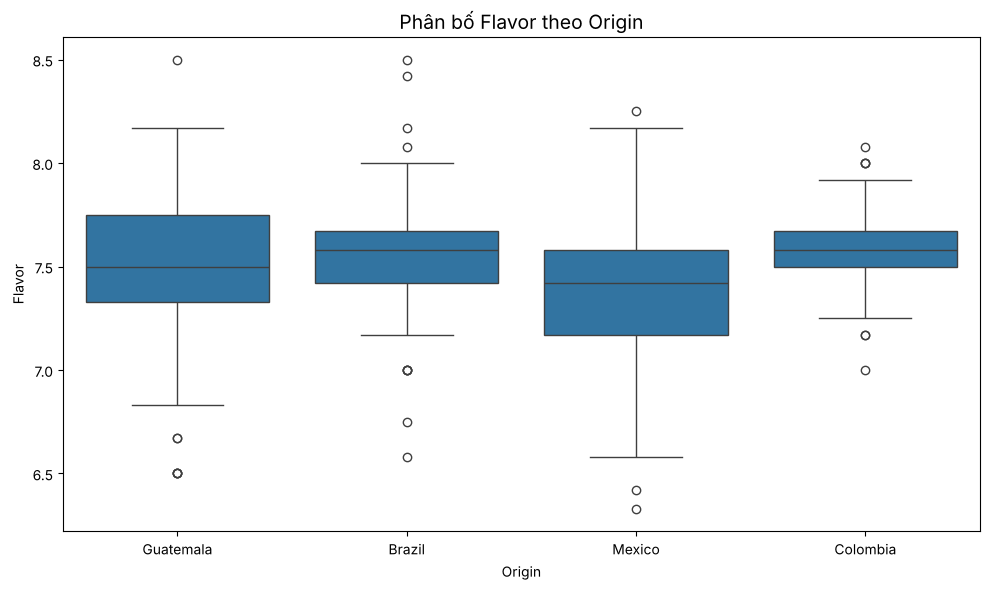

Đã lưu: ../figures/boxplots/boxplot_Flavor.png


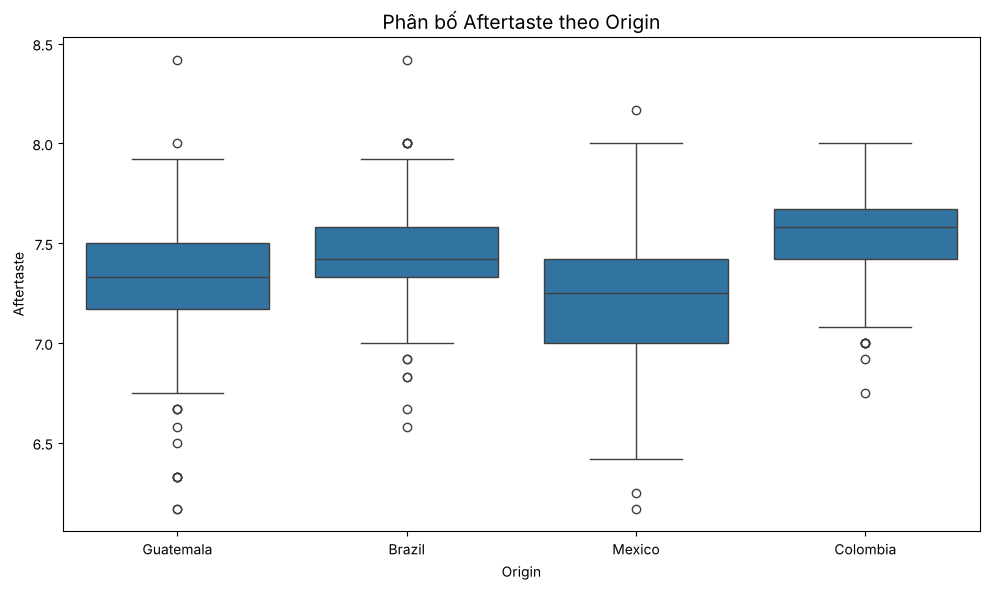

Đã lưu: ../figures/boxplots/boxplot_Aftertaste.png


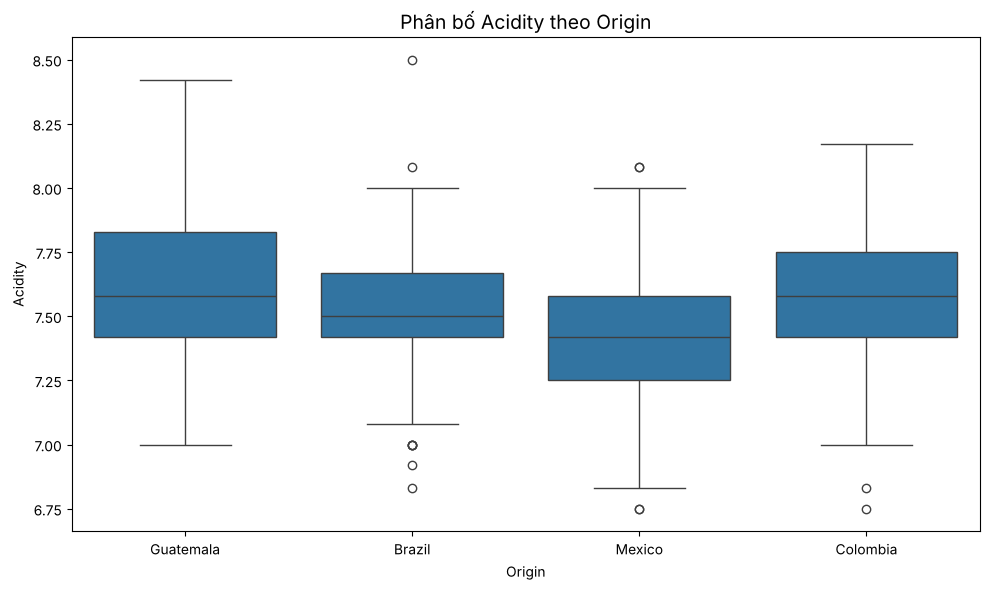

Đã lưu: ../figures/boxplots/boxplot_Acidity.png


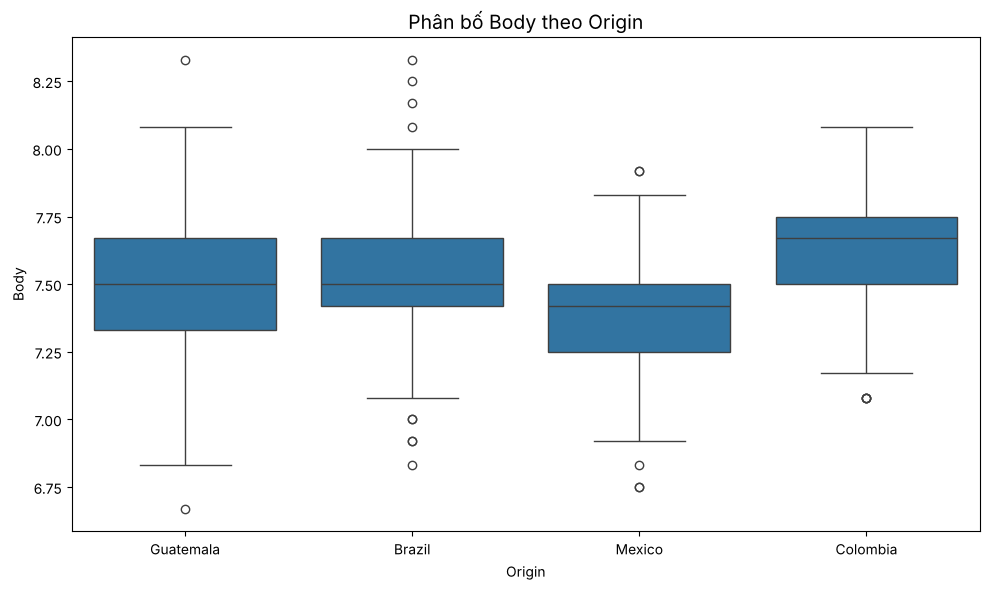

Đã lưu: ../figures/boxplots/boxplot_Body.png


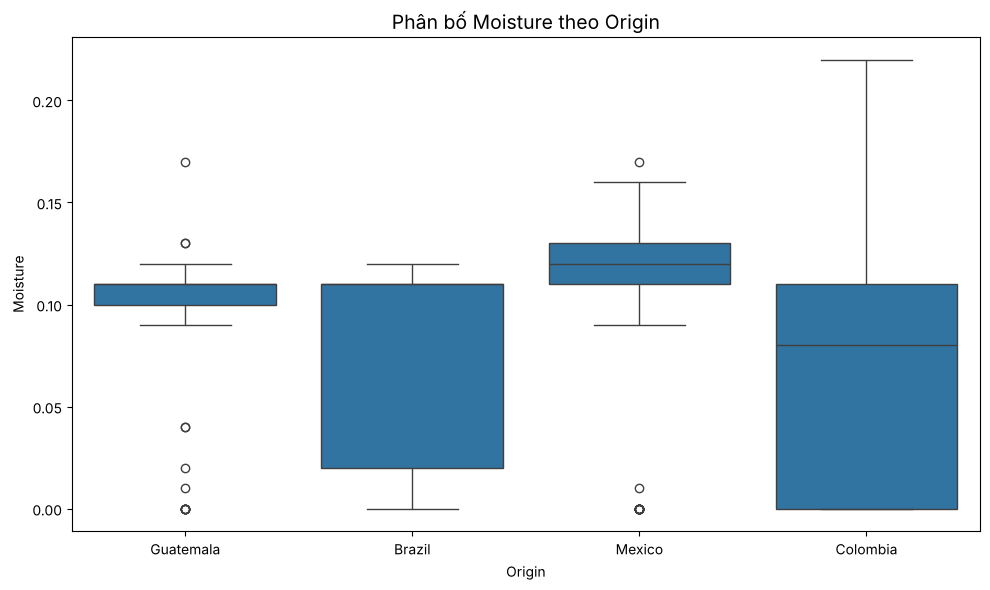

Đã lưu: ../figures/boxplots/boxplot_Moisture.png


In [5]:
# ============================================================
#
# Mục đích:
# So sánh phân bố của từng biến giữa 4 nhóm Origin.
#
# Boxplot thể hiện:
# - Median
# - Q1, Q3
# - Khoảng biến thiên
# - Các giá trị bất thường nếu có
#
# ============================================================

print("VẼ BOXPLOT")
for variable in dependent_vars:

    plt.figure(figsize=(10, 6))

    sns.boxplot(
        data=df,
        x=group_var,
        y=variable
    )

    plt.title(
        f"Phân bố {variable} theo Origin",
        fontsize=14
    )

    plt.xlabel("Origin")
    plt.ylabel(variable)

    plt.tight_layout()

    # Tên file
    file_path = (
       Path("..") / "figures" / "boxplots"
        / f"boxplot_{variable}.png"
    )

    file_path.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(
        file_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

    print("Đã lưu:", file_path)


## 5. BIỂU ĐỒ TRUNG BÌNH THEO ORIGIN

VẼ BIỂU ĐỒ TRUNG BÌNH

Giá trị trung bình:
           Fragrance    Flavor  Aftertaste   Acidity      Body  Moisture
Origin                                                                  
Brazil      7.553023  7.570155    7.450775  7.505891  7.538450  0.083721
Colombia    7.666722  7.595944    7.522333  7.571167  7.621056  0.062444
Guatemala   7.571086  7.521029    7.294057  7.604971  7.483543  0.101886
Mexico      7.457585  7.379025    7.228051  7.428347  7.380466  0.113602


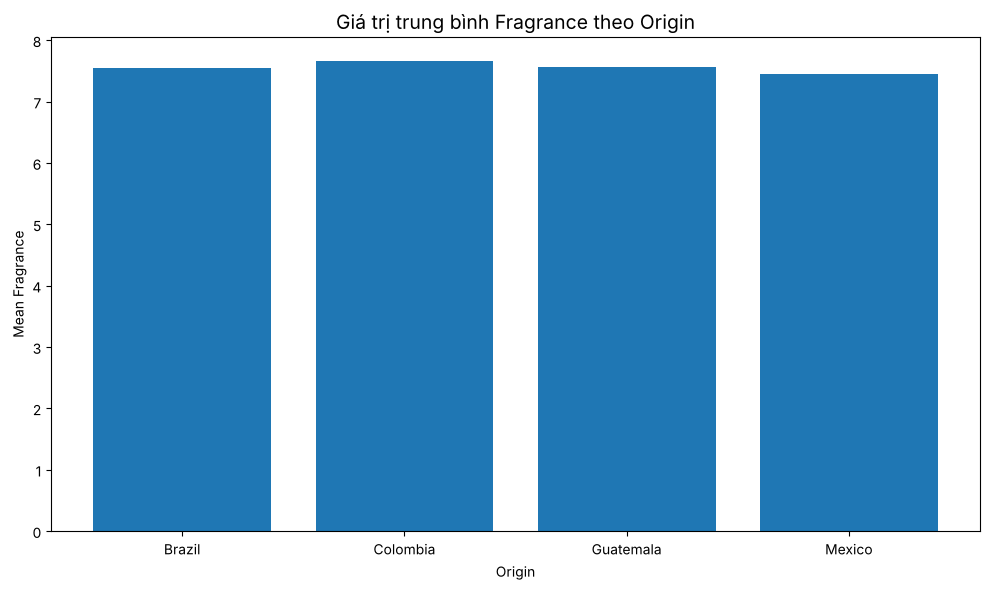

Đã lưu: ../figures/means/mean_Fragrance.png


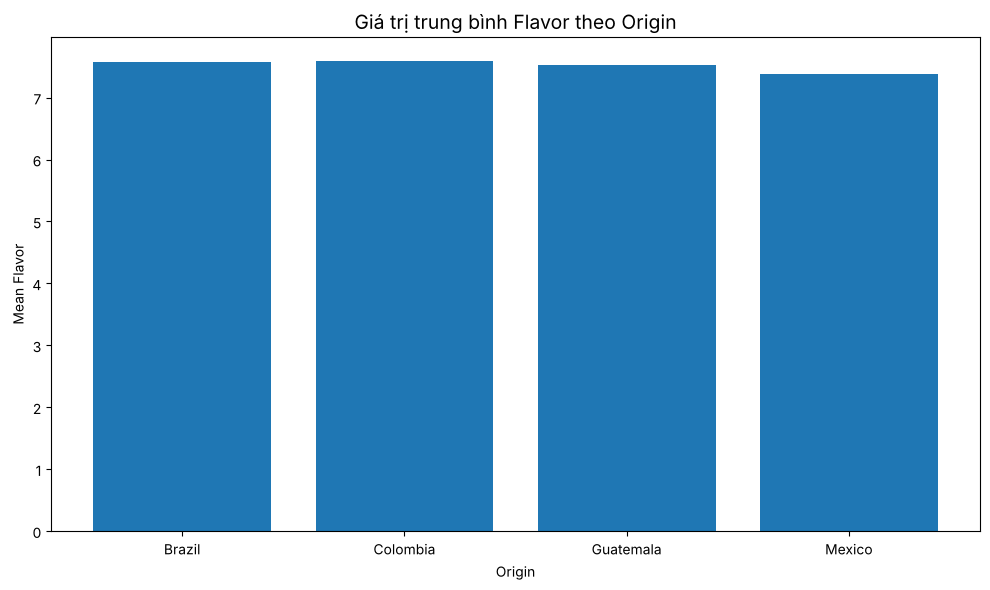

Đã lưu: ../figures/means/mean_Flavor.png


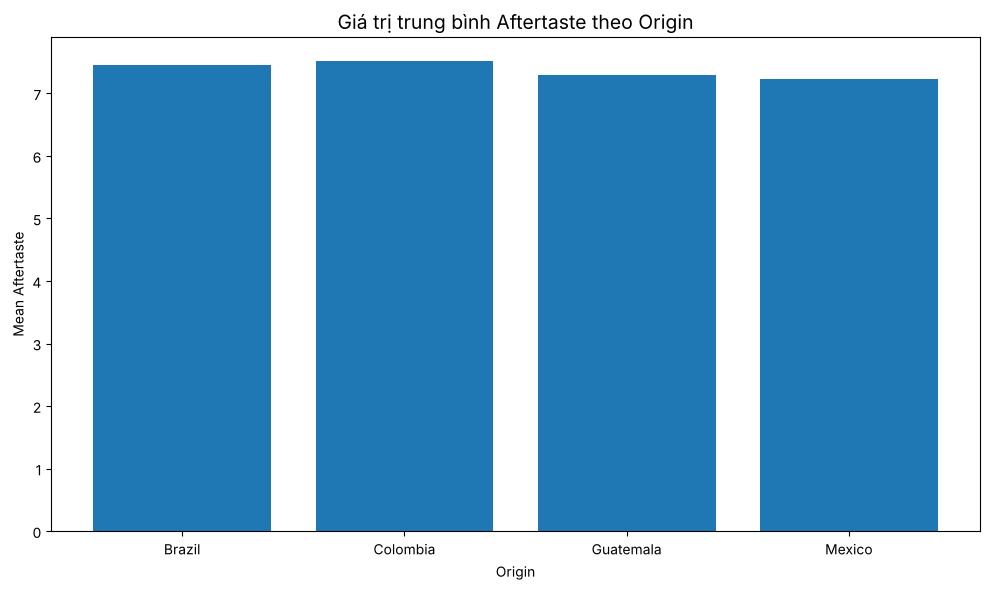

Đã lưu: ../figures/means/mean_Aftertaste.png


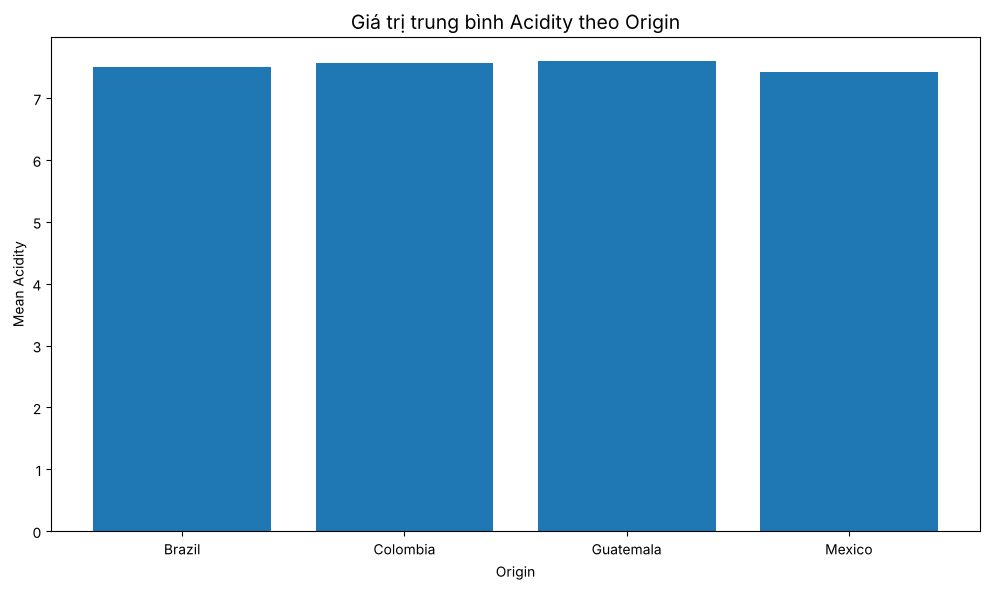

Đã lưu: ../figures/means/mean_Acidity.png


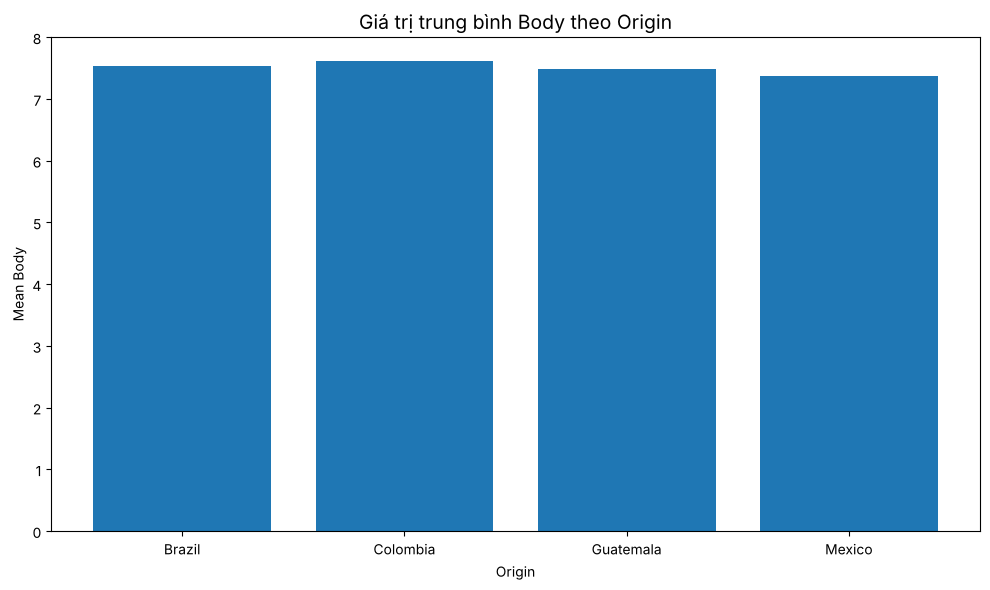

Đã lưu: ../figures/means/mean_Body.png


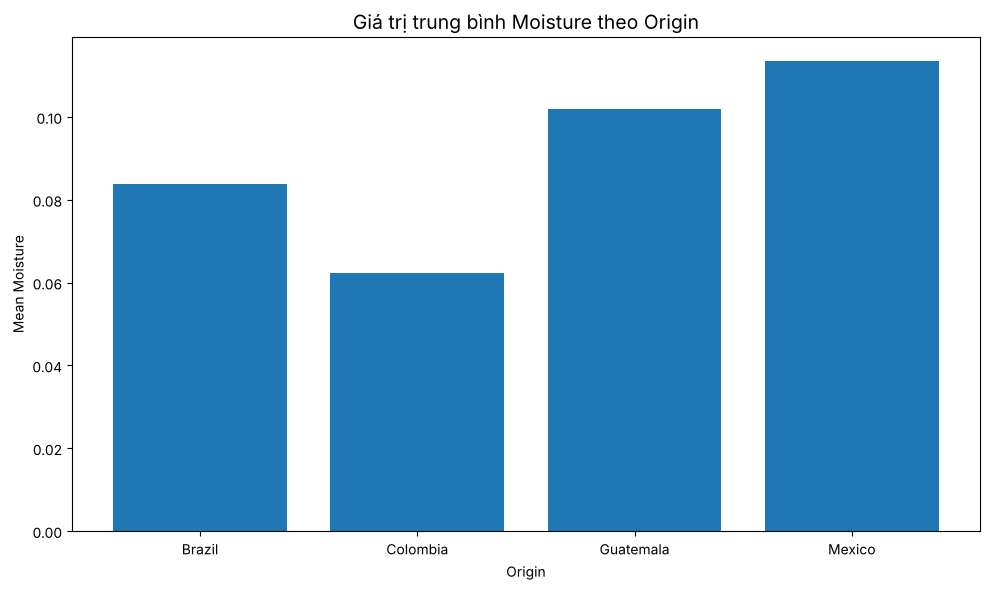

Đã lưu: ../figures/means/mean_Moisture.png


In [6]:
# ============================================================
#
# Mục đích:
# So sánh giá trị trung bình của từng biến
# giữa 4 nhóm Origin.
#
# ============================================================

print("VẼ BIỂU ĐỒ TRUNG BÌNH")

group_mean = (
    df
    .groupby(group_var)[dependent_vars]
    .mean()
)

print("\nGiá trị trung bình:")
print(group_mean)


# ------------------------------------------------------------
# Vẽ từng biến
# ------------------------------------------------------------

for variable in dependent_vars:

    plt.figure(figsize=(10, 6))

    plt.bar(
        group_mean.index,
        group_mean[variable]
    )

    plt.title(
        f"Giá trị trung bình {variable} theo Origin",
        fontsize=14
    )

    plt.xlabel("Origin")
    plt.ylabel(f"Mean {variable}")

    plt.xticks(rotation=0)

    plt.tight_layout()

    file_path = (
        Path("..") / "figures" / "means"
        / f"mean_{variable}.png"
    )

    file_path.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(
        file_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

    print("Đã lưu:", file_path)


## 6. BIỂU ĐỒ SO SÁNH 6 BIẾN

VẼ BIỂU ĐỒ SO SÁNH 6 BIẾN


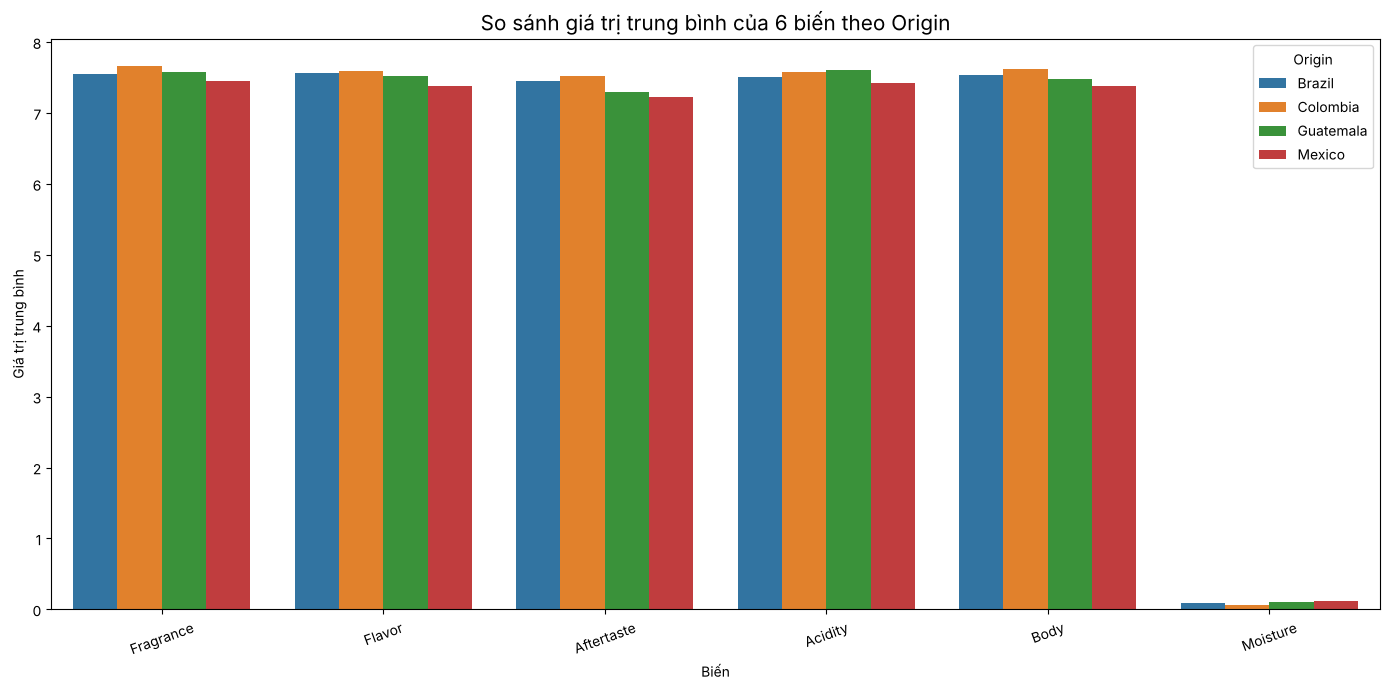

Đã lưu: ../figures/means/mean_comparison_all_variables.png


In [7]:
# ============================================================
#
# Chuyển dữ liệu từ dạng rộng sang dạng dài
# để tạo biểu đồ tổng hợp.
#
# ============================================================
print("VẼ BIỂU ĐỒ SO SÁNH 6 BIẾN")

mean_long = (
    group_mean
    .reset_index()
    .melt(
        id_vars=group_var,
        value_vars=dependent_vars,
        var_name="Variable",
        value_name="Mean"
    )
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=mean_long,
    x="Variable",
    y="Mean",
    hue="Origin"
)

plt.title(
    "So sánh giá trị trung bình của 6 biến theo Origin",
    fontsize=15
)

plt.xlabel("Biến")
plt.ylabel("Giá trị trung bình")

plt.xticks(rotation=20)

plt.tight_layout()

file_path = (
    Path("..") / "figures" / "means"
    / "mean_comparison_all_variables.png"
)

file_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(
    file_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()

print("Đã lưu:", file_path)


## 7. HEATMAP TƯƠNG QUAN

VẼ HEATMAP TƯƠNG QUAN

Ma trận tương quan:
            Fragrance    Flavor  Aftertaste   Acidity      Body  Moisture
Fragrance    1.000000  0.746585    0.690462  0.608692  0.581132 -0.178464
Flavor       0.746585  1.000000    0.841979  0.703278  0.629891 -0.172400
Aftertaste   0.690462  0.841979    1.000000  0.630651  0.664310 -0.232141
Acidity      0.608692  0.703278    0.630651  1.000000  0.570865 -0.158005
Body         0.581132  0.629891    0.664310  0.570865  1.000000 -0.238771
Moisture    -0.178464 -0.172400   -0.232141 -0.158005 -0.238771  1.000000


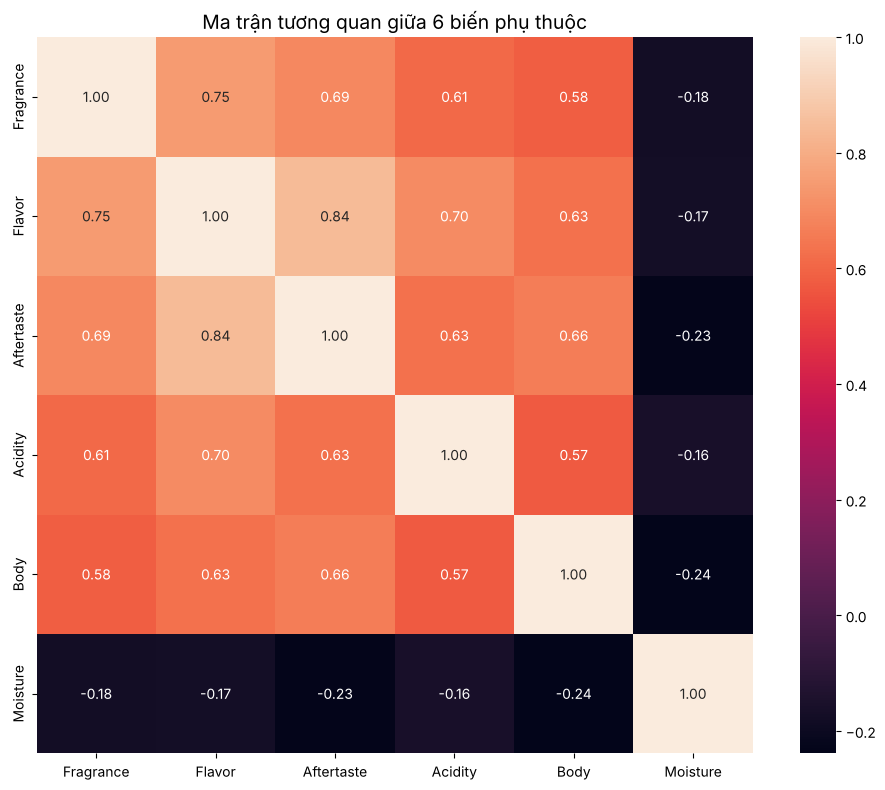

Đã lưu: ../figures/correlations/correlation_heatmap.png


In [8]:
# ============================================================
#
# Mục đích:
# Kiểm tra mối tương quan giữa 6 biến phụ thuộc.
#
# ============================================================
print("VẼ HEATMAP TƯƠNG QUAN")
correlation = df[dependent_vars].corr()

print("\nMa trận tương quan:")
print(correlation)

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    square=True
)

plt.title(
    "Ma trận tương quan giữa 6 biến phụ thuộc",
    fontsize=14
)

plt.tight_layout()

file_path = (
   Path("..") / "figures" / "correlations"
    / "correlation_heatmap.png"
)

file_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(
    file_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()

print("Đã lưu:", file_path)


## 7b. PAIRPLOT (MA TRẬN BIỂU ĐỒ PHÂN TÁN)

VẼ PAIRPLOT


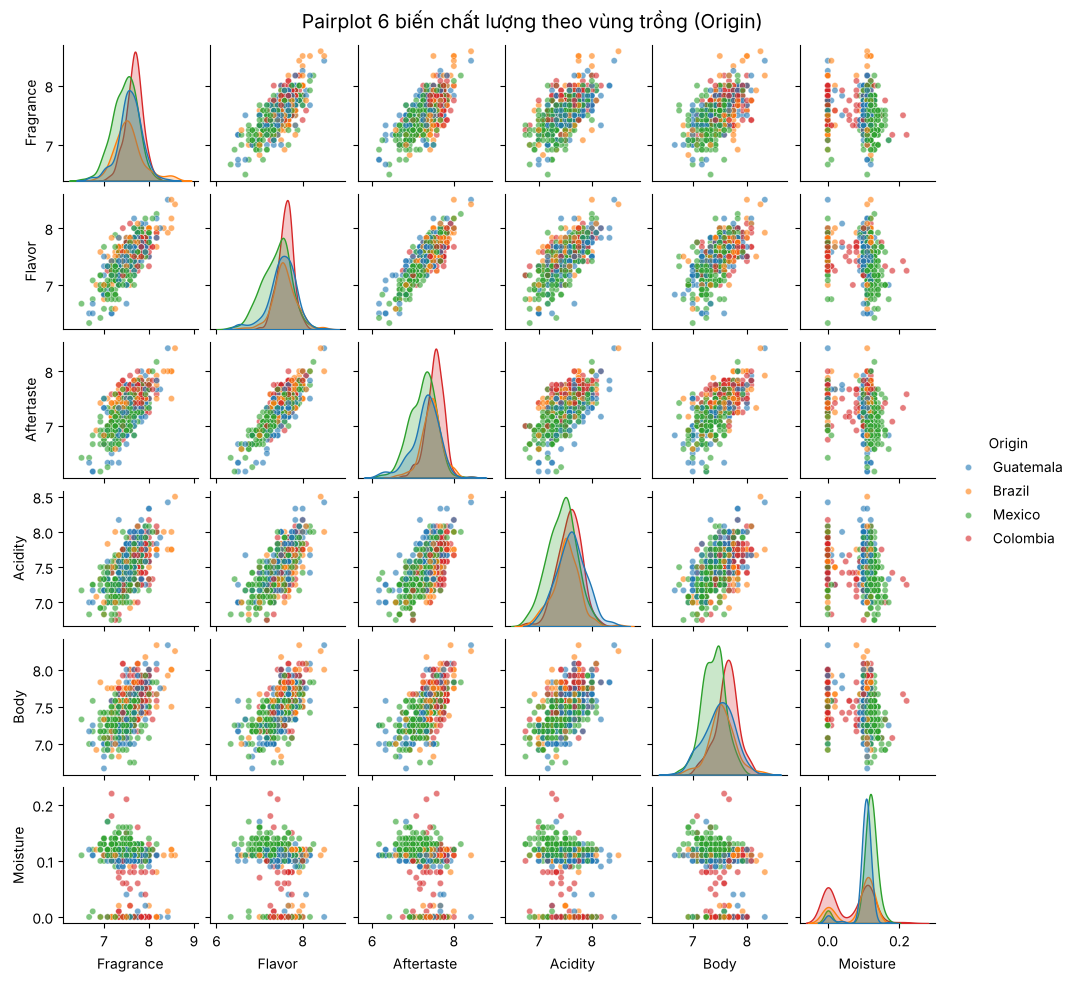

Đã lưu: ../figures/correlations/pairplot.png


In [9]:
# ============================================================
# Mục đích:
# Quan sát đồng thời quan hệ giữa từng cặp biến và
# mức độ tách/chồng lấp của 4 vùng trồng (Origin) trên mỗi cặp.
# Đường chéo: phân bố (KDE) của từng biến theo Origin.
# ============================================================
print("VẼ PAIRPLOT")

pair_grid = sns.pairplot(
    df,
    vars=dependent_vars,
    hue=group_var,
    diag_kind="kde",
    plot_kws={"alpha": 0.6, "s": 20},
    height=1.6
)
pair_grid.figure.suptitle(
    "Pairplot 6 biến chất lượng theo vùng trồng (Origin)",
    y=1.02,
    fontsize=14
)

pair_path = Path("..") / "figures" / "correlations" / "pairplot.png"
pair_path.parent.mkdir(parents=True, exist_ok=True)
pair_grid.savefig(pair_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Đã lưu: {pair_path}")

## 8. KẾT THÚC

In [10]:
print("HOÀN THÀNH TRỰC QUAN HÓA")
print("\nTất cả hình được lưu tại:")
print(Path("..") / "figures")

HOÀN THÀNH TRỰC QUAN HÓA

Tất cả hình được lưu tại:
../figures
